# BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS - EDA)
**Dự án:** Xây dựng Hệ thống Dự đoán Điểm thi của Sinh viên bằng Học máy  
**Học phần:** Trí tuệ nhân tạo  
**Thành viên phụ trách:** Thành viên 2 – Phân tích dữ liệu và trực quan hóa (20%)  
**Mục tiêu:** Chuyển dữ liệu thô thành các phát hiện có bằng chứng khoa học, nhận diện dữ liệu thiếu, phát hiện điểm bất thường, kiểm tra tương quan và đề xuất quy tắc miền hợp lệ cho các thành viên trong nhóm.


In [1]:
import sys
from pathlib import Path

# Thêm thư mục gốc vào sys.path để import src
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị bảng và font đồ thị chuẩn
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.autolayout": True
})

print("-> Thư viện đã sẵn sàng!")


-> Thư viện đã sẵn sàng!


## 1. Khảo sát Tổng quan Bộ dữ liệu
Đọc tệp `StudentPerformanceFactors.csv` từ thư mục `data/raw/` theo đúng nguyên tắc: **Không chỉnh sửa trực tiếp dữ liệu gốc**.


In [2]:
csv_path = Path("../data/raw/StudentPerformanceFactors.csv")
if not csv_path.exists():
    csv_path = Path("data/raw/StudentPerformanceFactors.csv")

df = pd.read_csv(csv_path)

print(f"Kích thước dữ liệu: {df.shape[0]:,} dòng, {df.shape[1]} cột")
print(f"Số dòng trùng lặp: {df.duplicated().sum()}")
display(df.head(5))


Kích thước dữ liệu: 6,607 dòng, 20 cột
Số dòng trùng lặp: 0


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## 2. Thống kê Chi tiết 19 Đặc trưng và Biến Mục tiêu
Phân loại các biến định lượng (Numeric) và biến định tính (Categorical), đo lường số lượng giá trị duy nhất và tỷ lệ dữ liệu thiếu.


In [3]:
from src.eda import generate_data_summary

summary_df = generate_data_summary(df, output_path=Path("../reports/data_summary.csv"))
display(summary_df)


-> Đã lưu bảng tóm tắt dữ liệu: ..\reports\data_summary.csv


,Thuộc_tính,Kiểu_dữ_liệu,Số_lượng_thiếu,Tỷ_lệ_thiếu_%,Số_giá_trị_duy_nhất,Miền_giá_trị_hoặc_Nhóm,Min,Max,Mean,Median,Std
0,Hours_Studied,int64,0,0.00,41,"[1.0, 44.0]",1.0,44.0,19.98,20.0,5.99
1,Attendance,int64,0,0.00,41,"[60.0, 100.0]",60.0,100.0,79.98,80.0,11.55
2,Parental_Involvement,str,0,0.00,3,"Low, Medium, High",NaN,NaN,NaN,NaN,NaN
3,Access_to_Resources,str,0,0.00,3,"High, Medium, Low",NaN,NaN,NaN,NaN,NaN
4,Extracurricular_Activities,str,0,0.00,2,"No, Yes",NaN,NaN,NaN,NaN,NaN
5,Sleep_Hours,int64,0,0.00,7,"[4.0, 10.0]",4.0,10.0,7.03,7.0,1.47
6,Previous_Scores,int64,0,0.00,51,"[50.0, 100.0]",50.0,100.0,75.07,75.0,14.40
7,Motivation_Level,str,0,0.00,3,"Low, Medium, High",NaN,NaN,NaN,NaN,NaN
8,Internet_Access,str,0,0.00,2,"Yes, No",NaN,NaN,NaN,NaN,NaN
9,Tutoring_Sessions,int64,0,0.00,9,"[0.0, 8.0]",0.0,8.0,1.49,1.0,1.23


## 3. Phân tích Biến Mục tiêu `Exam_Score` & Điểm Bất Thường
### Quan sát & Suy diễn:
1. **Phân bố:** Điểm thi dao động trong khoảng từ 55 đến 101 điểm. Phân bố điểm mang dáng dấp của phân bố chuẩn (chuông đối xứng) quanh mức trung bình 67.23 điểm và trung vị 67.00 điểm.
2. **Điểm bất thường (Anomaly):** Phát hiện **1 bản ghi có điểm số bằng 101**. Trong khi thang điểm đánh giá học tập chuẩn tối đa là 100.
3. **Đề xuất xử lý:** Bàn giao cho Người 1 (Data Validation) và Người 3 (Preprocessing) áp dụng giới hạn trần (clip) về 100 điểm hoặc loại bỏ bản ghi này để tránh làm lệch hàm mất mát của mô hình hồi quy.


-> Đã lưu biểu đồ: 01_exam_score_distribution.png


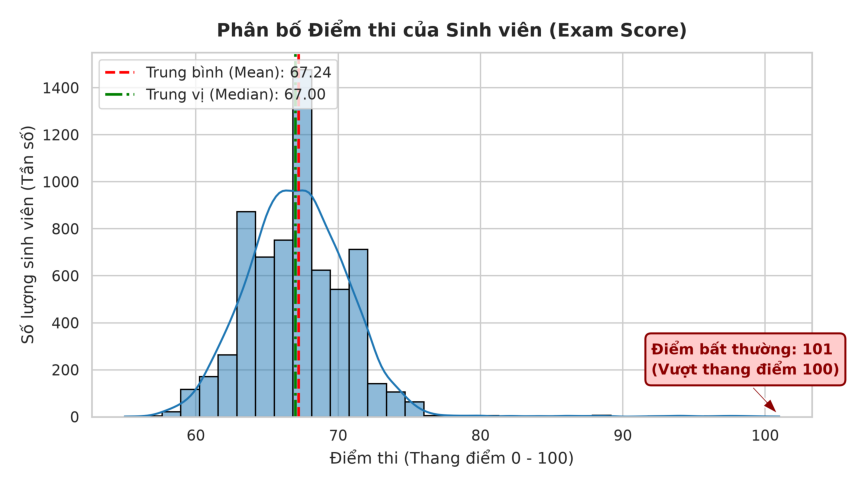

In [4]:
from src.eda import plot_target_distribution

save_p1 = plot_target_distribution(df, output_dir=Path("../reports/figures"))
img1 = plt.imread(save_p1)
plt.figure(figsize=(9, 5))
plt.imshow(img1)
plt.axis('off')
plt.show()


## 4. Phân tích Tỷ lệ Dữ liệu Thiếu (Missing Values)
### Nhận xét cụ thể:
* Chỉ có **3 trên 20 thuộc tính** có giá trị bị thiếu (NaN):
  - `Parental_Education_Level`: Thiếu 90 bản ghi (chiếm **1.36%**)
  - `Teacher_Quality`: Thiếu 78 bản ghi (chiếm **1.18%**)
  - `Distance_from_Home`: Thiếu 67 bản ghi (chiếm **1.01%**)
* Cả 3 thuộc tính này đều là **biến phân loại** (Categorical). Tỷ lệ thiếu rất nhỏ (< 2%), hoàn toàn phù hợp để Người 3 áp dụng kỹ thuật điền giá trị xuất hiện nhiều nhất (`SimpleImputer(strategy='most_frequent')`) mà không làm méo mó bản chất phân bố dữ liệu.


-> Đã lưu biểu đồ: 02_missing_values_summary.png


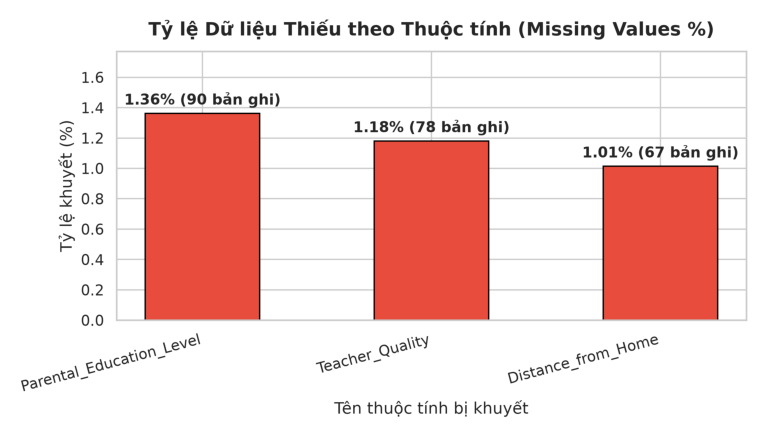

In [5]:
from src.eda import plot_missing_values

save_p2 = plot_missing_values(df, output_dir=Path("../reports/figures"))
img2 = plt.imread(save_p2)
plt.figure(figsize=(8, 4.5))
plt.imshow(img2)
plt.axis('off')
plt.show()


## 5. Ma trận Tương quan Giữa các Biến Số (Correlation Analysis)
### Lưu ý Phương pháp luận:
> **Tương quan tuyến tính (Pearson Correlation) KHÔNG đồng nghĩa với mối quan hệ nhân quả (Causation).**  
> Hệ số tương quan $r > 0$ chỉ ra rằng hai biến có xu hướng biến thiên cùng chiều, chứ không khẳng định biến này là nguyên nhân trực tiếp gây ra biến kia.

### Nhận xét Hệ số Tương quan với `Exam_Score`:
1. **Attendance (Chuyên cần):** Tương quan dương đáng kể ($r pprox 0.582$). Sinh viên đi học đầy đủ thường nắm bắt bài tốt hơn.
2. **Hours_Studied (Số giờ tự học):** Tương quan dương rõ rệt ($r pprox 0.447$). Thời gian đầu tư ôn tập có đóng góp lớn đến kết quả.
3. **Previous_Scores (Điểm trước đây):** Tương quan thuận ($r pprox 0.187$), phản ánh nền tảng kiến thức tích lũy từ trước.
4. **Tutoring_Sessions (Số buổi phụ đạo):** Tương quan dương nhẹ ($r pprox 0.165$).
5. **Sleep_Hours & Physical_Activity:** Tương quan gần như bằng 0 ($|r| < 0.05$), cho thấy giấc ngủ và vận động không có tác động tuyến tính trực tiếp đến điểm thi.


-> Đã lưu biểu đồ: 03_correlation_heatmap.png


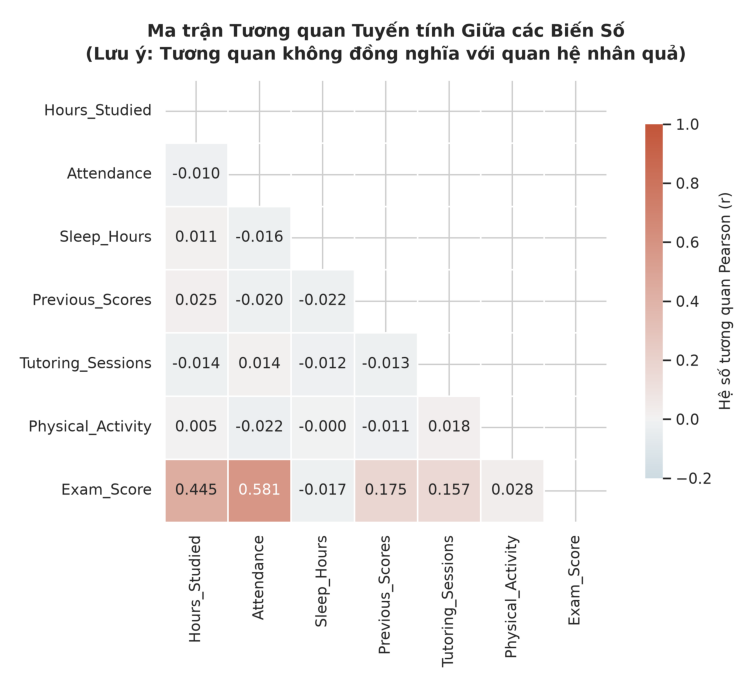

In [6]:
from src.eda import plot_correlation_heatmap

save_p3 = plot_correlation_heatmap(df, output_dir=Path("../reports/figures"))
img3 = plt.imread(save_p3)
plt.figure(figsize=(9, 7))
plt.imshow(img3)
plt.axis('off')
plt.show()


## 6. Kiểm tra Ngoại lệ (Outlier Detection) Bằng Boxplot
Sử dụng tiêu chuẩn khoảng tứ phân vị (Interquartile Range - $IQR$):
$$\text{Lower Bound} = Q_1 - 1.5 \times IQR, \quad \text{Upper Bound} = Q_3 + 1.5 \times IQR$$


-> Đã lưu biểu đồ: 04_numeric_features_boxplots.png


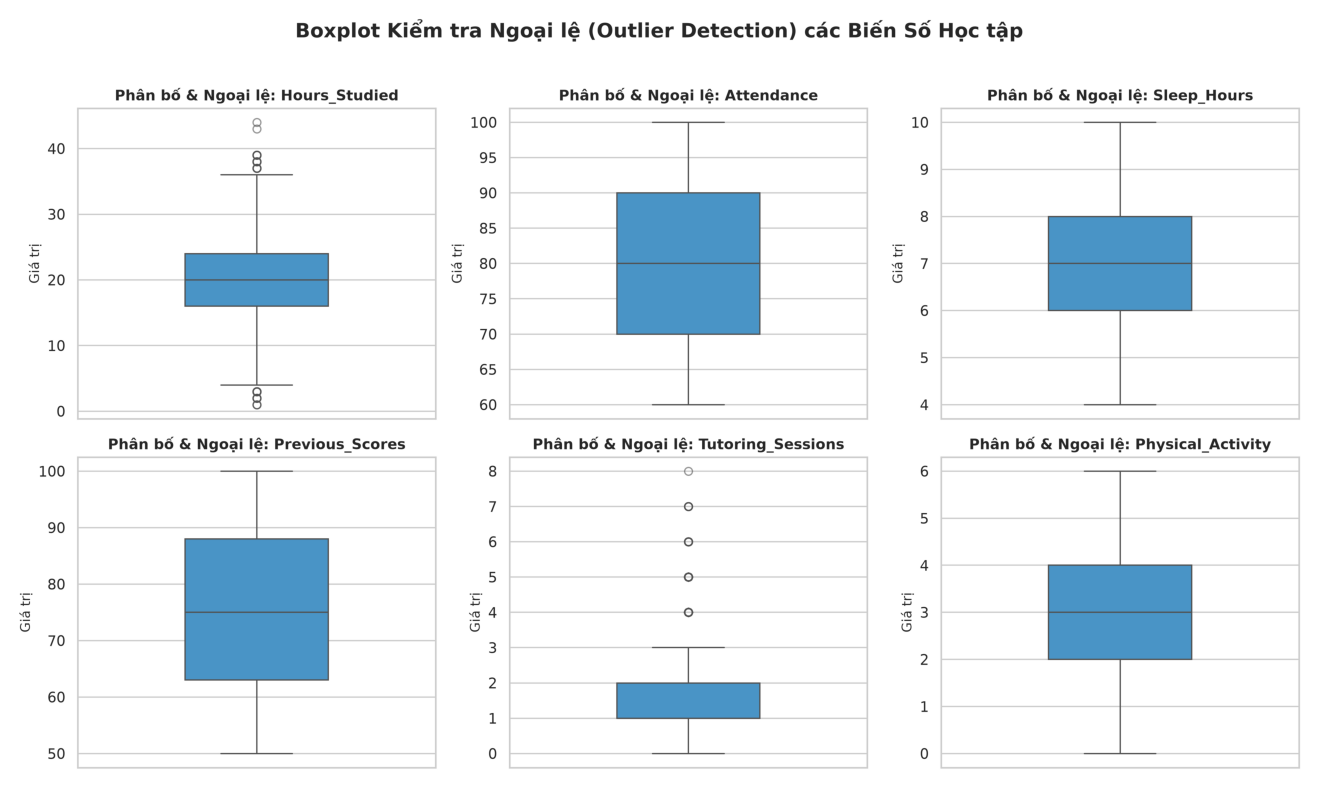

In [7]:
from src.eda import plot_numeric_boxplots

save_p4 = plot_numeric_boxplots(df, output_dir=Path("../reports/figures"))
img4 = plt.imread(save_p4)
plt.figure(figsize=(14, 8))
plt.imshow(img4)
plt.axis('off')
plt.show()


## 7. Khảo sát Hai Yếu Tố Quyết Định: Giờ Học và Chuyên Cần
Vẽ biểu đồ tán xạ (Scatter plot) kết hợp đường xu hướng tuyến tính (Trendline) để quan sát rõ hơn độ dốc ảnh hưởng đến `Exam_Score`.


-> Đã lưu biểu đồ: 05_hours_attendance_vs_exam_score.png


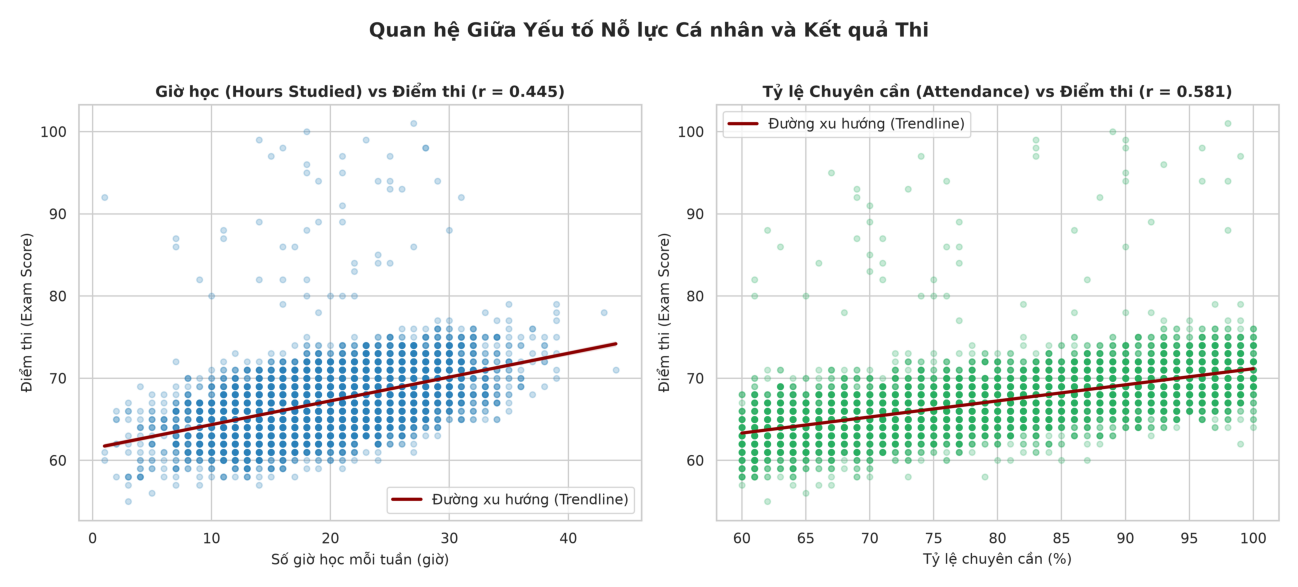

In [8]:
from src.eda import plot_key_factors_vs_score

save_p5 = plot_key_factors_vs_score(df, output_dir=Path("../reports/figures"))
img5 = plt.imread(save_p5)
plt.figure(figsize=(14, 6))
plt.imshow(img5)
plt.axis('off')
plt.show()


## 8. So sánh Điểm Thi Trung Bình theo các Nhóm Phân Loại
Khảo sát các yếu tố môi trường và tâm lý:
* **Motivation Level (Mức độ động lực):** Low vs Medium vs High.
* **Access to Resources (Tiếp cận tài nguyên):** Tài liệu, sách vở, thiết bị học tập.
* **Teacher Quality (Chất lượng giảng viên):** Đánh giá về giáo viên giảng dạy.
* **Parental Involvement (Sự quan tâm của phụ huynh):** Mức độ đồng hành của gia đình.


-> Đã lưu biểu đồ: 06_categorical_factors_comparison.png


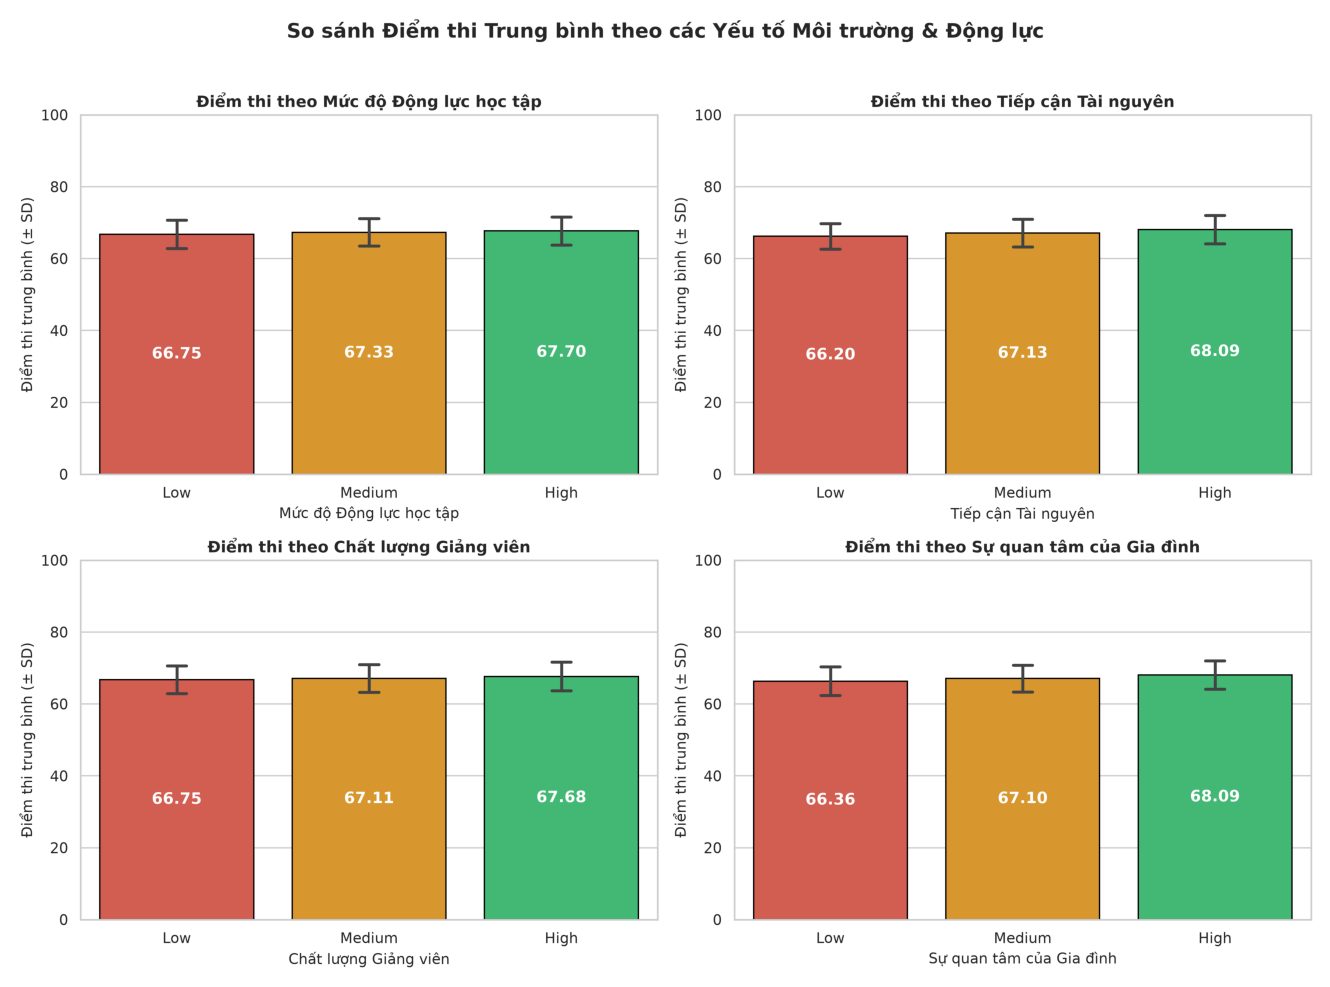

In [9]:
from src.eda import plot_categorical_comparisons

save_p6 = plot_categorical_comparisons(df, output_dir=Path("../reports/figures"))
img6 = plt.imread(save_p6)
plt.figure(figsize=(14, 10))
plt.imshow(img6)
plt.axis('off')
plt.show()


## 9. Đề xuất Miền Hợp Lệ cho Module Kiểm tra Dữ liệu và Giao diện (Mốc Bàn Giao H1)
Bảng quy định giá trị min/max của biến số và danh sách danh mục hợp lệ chuyển giao cho:
- **Người 1:** Tích hợp kiểm tra tính hợp lệ khi tải file dữ liệu thô (`src/data_validation.py`).
- **Người 5:** Tích hợp bộ chọn giới hạn (Slider, Selectbox) trên ứng dụng Streamlit (`app.py`).


In [10]:
from src.eda import get_proposed_input_rules
import json

rules = get_proposed_input_rules(df)
rules_file = Path("../reports/proposed_input_rules.json")
with open(rules_file, "w", encoding="utf-8") as f:
    json.dump(rules, f, indent=2, ensure_ascii=False)

print("Quy tắc miền hợp lệ đã sẵn sàng bàn giao (Mốc H1):")
print(json.dumps(rules, indent=2, ensure_ascii=False)[:600] + "\n...")


Quy tắc miền hợp lệ đã sẵn sàng bàn giao (Mốc H1):
{
  "numeric_ranges": {
    "Hours_Studied": {
      "min": 1.0,
      "max": 44.0,
      "recommended_min": 0.0,
      "recommended_max": 44.0,
      "unit": "giờ"
    },
    "Attendance": {
      "min": 60.0,
      "max": 100.0,
      "recommended_min": 0.0,
      "recommended_max": 100.0,
      "unit": "%"
    },
    "Sleep_Hours": {
      "min": 4.0,
      "max": 10.0,
      "recommended_min": 0.0,
      "recommended_max": 10.0,
      "unit": "giờ"
    },
    "Previous_Scores": {
      "min": 50.0,
      "max": 100.0,
      "recommended_min": 0.0,
      "recommended_max": 100.0,
      "uni
...


## 10. Tổng Kết và Chuyển Giao Công Việc
1. **Dữ liệu thiếu:** Chỉ xảy ra ở 3 cột phân loại (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`) với tỷ lệ < 1.5%. Khuyến nghị Người 3 điền bằng giá trị xuất hiện nhiều nhất (`most_frequent`).
2. **Điểm bất thường:** Phát hiện giá trị `101` ở cột `Exam_Score`. Đề xuất Người 1 và Người 3 gán trần về `100`.
3. **Đặc trưng quan trọng nhất:** `Attendance` ($r = 0.582$) và `Hours_Studied` ($r = 0.447$) là 2 yếu tố tương quan mạnh nhất với điểm thi.
4. **Miền giá trị hợp lệ:** Đã lưu tại `reports/proposed_input_rules.json` và bảng tóm tắt tại `reports/data_summary.csv`.
